# EN3150 Assignment 03
## Resource-Constrained CNN for Fashion-MNIST

1. Import libraries
2. Load Fashion-MNIST
3. Understand the data
4. Split data into 70% train, 15% validation, 15% test
5. Preprocess the images
6. Build Model A - Standard CNN
7. Build Model B - Lightweight CNN
8. Compare trainable parameters
9. Compare optimizers
10. Train Model A and Model B
11. Plot loss curves
12. Evaluate both models
13. Compare model size, training time and accuracy
14. Fine-tune MobileNetV2
15. Fine-tune EfficientNetB0
16. Final comparison

## 1. Import Libraries

We first import the libraries needed for the project.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

## 2. Load Fashion-MNIST

Fashion-MNIST has 70,000 grayscale clothing images.

Each image is 28 x 28 pixels, so it is already smaller than the assignment limit of 64 x 64 pixels.

In [2]:
(x1, y1), (x2, y2) = keras.datasets.fashion_mnist.load_data()

# Combine the original train and test sets.
# We do this because our assignment needs a new 70/15/15 split.

images = np.concatenate((x1, x2))
labels = np.concatenate((y1, y2))

print("Images:", images.shape)
print("Labels:", labels.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Images: (70000, 28, 28)
Labels: (70000,)


## 3. Class Names

In [3]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

## 4. View Some Images

Before training, we look at a few samples from the dataset.

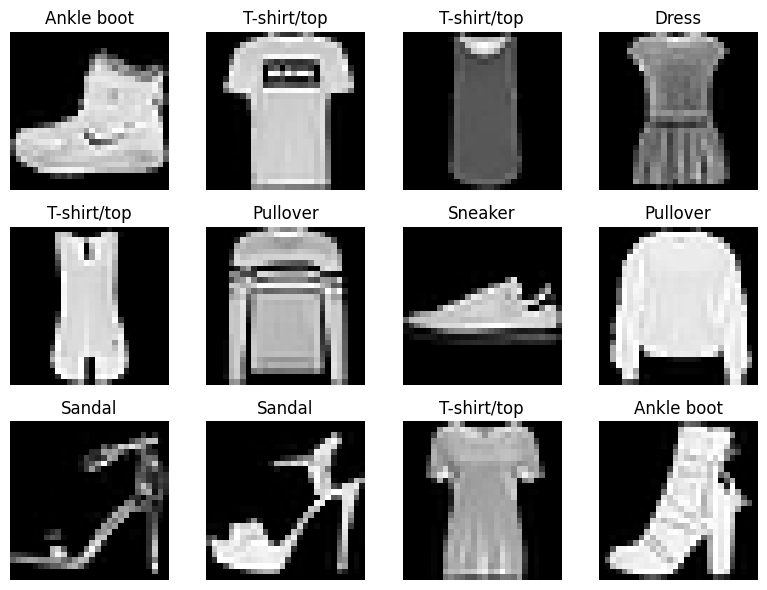

In [4]:
plt.figure(figsize=(8, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(class_names[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 5. Check Class Distribution

Fashion-MNIST is a balanced dataset.  
We check how many images belong to each class.

In [5]:
counts = np.bincount(labels)

for i in range(10):
    print(i, class_names[i], ":", counts[i])

0 T-shirt/top : 7000
1 Trouser : 7000
2 Pullover : 7000
3 Dress : 7000
4 Coat : 7000
5 Sandal : 7000
6 Shirt : 7000
7 Sneaker : 7000
8 Bag : 7000
9 Ankle boot : 7000


## 6. Split the Data

The assignment requires:

- 70% training
- 15% validation
- 15% testing

We use `stratify=labels` so all sets keep approximately the same class distribution.

In [6]:
x_train_raw, x_temp_raw, y_train, y_temp = train_test_split(
    images,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

x_val_raw, x_test_raw, y_val, y_test = train_test_split(
    x_temp_raw,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", x_train_raw.shape)
print("Validation:", x_val_raw.shape)
print("Testing:", x_test_raw.shape)

Training: (49000, 28, 28)
Validation: (10500, 28, 28)
Testing: (10500, 28, 28)


## 7. Data Preprocessing

### Normalization

Pixel values are originally between 0 and 255.

We divide by 255 so the values become between 0 and 1.

### Add Channel Dimension

Fashion-MNIST is grayscale, so each image has one channel.

CNN input shape becomes:

`28 x 28 x 1`

In [7]:
x_train = x_train_raw.astype("float32") / 255.0
x_val = x_val_raw.astype("float32") / 255.0
x_test = x_test_raw.astype("float32") / 255.0

x_train = np.expand_dims(x_train, axis=-1)
x_val = np.expand_dims(x_val, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Training:", x_train.shape)
print("Validation:", x_val.shape)
print("Testing:", x_test.shape)

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Training: (49000, 28, 28, 1)
Validation: (10500, 28, 28, 1)
Testing: (10500, 28, 28, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


# Model A - Standard CNN

## 8. Build Model A

Model A uses normal 2D convolution layers and max-pooling layers.

We use ReLU inside the network because it is simple and computationally cheap.

The final layer uses Softmax because we have 10 classes.

In [8]:
model_a = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(16, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model_a.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       100,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,866 (413.54 KB)

 Trainable params: 105,866 (413.54 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Calculate Parameters of Model A

For a normal convolution layer:

\[
\text{Parameters} =
(K_h K_w C_{in}+1)C_{out}
\]

### Conv2D 1

\[
(3\times3\times1+1)\times16 = 160
\]

### Conv2D 2

\[
(3\times3\times16+1)\times32 = 4,640
\]

After the two pooling layers:

\[
28\times28 \rightarrow 14\times14 \rightarrow 7\times7
\]

So Flatten gives:

\[
7\times7\times32 = 1568
\]

### Dense 64

\[
(1568+1)\times64 = 100,416
\]

### Output Layer

\[
(64+1)\times10 = 650
\]

### Total

\[
160+4640+100416+650 = 105,866
\]

In [9]:
print("Model A parameters:", model_a.count_params())

Model A parameters: 105866


# Model B - Lightweight CNN

## 10. Build Model B

Model B uses depthwise separable convolutions.

A depthwise separable convolution does the work in two steps:

1. Depthwise convolution
2. 1 x 1 pointwise convolution

This uses fewer parameters and fewer operations than a normal convolution.

In [10]:
model_b = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(16, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.SeparableConv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.SeparableConv2D(64, (3, 3), padding="same", activation="relu"),

    layers.GlobalAveragePooling2D(),

    layers.Dense(32, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model_b.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d                │ (None, 14, 14, 32)     │           688 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_1              │ (None, 7, 7, 64)       │         2,400 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,658 (22.10 KB)

 Trainable params: 5,658 (22.10 KB)

 Non-trainable params: 0 (0.00 B)

## 11. Calculate Parameters of Model B

### First Normal Conv2D

\[
(3\times3\times1+1)\times16 = 160
\]

### First Separable Conv2D

Depthwise part:

\[
3\times3\times16 = 144
\]

Pointwise part:

\[
16\times32 = 512
\]

Bias:

\[
32
\]

Total:

\[
144+512+32=688
\]

### Second Separable Conv2D

\[
3\times3\times32 + 32\times64 + 64
\]

\[
288+2048+64 = 2400
\]

### Dense 32

\[
(64+1)\times32 = 2080
\]

### Output Layer

\[
(32+1)\times10=330
\]

### Total

\[
160+688+2400+2080+330=5658
\]

This is much lower than the assignment limit of 100,000 trainable parameters.

In [11]:
print("Model B parameters:", model_b.count_params())

if model_b.count_params() < 100000:
    print("Model B is below 100,000 parameters.")
else:
    print("Model B is too large.")

Model B parameters: 5658
Model B is below 100,000 parameters.


# Optimizer Comparison

## 12. Adam

We first train Model B using Adam.

Learning rate = 0.001

In [12]:
adam_model = keras.models.clone_model(model_b)

adam_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

adam_history = adam_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=128,
    verbose=2
)

Epoch 1/20
383/383 - 16s - 41ms/step - accuracy: 0.4217 - loss: 1.5798 - val_accuracy: 0.6187 - val_loss: 1.0460
Epoch 2/20
383/383 - 2s - 4ms/step - accuracy: 0.6620 - loss: 0.9367 - val_accuracy: 0.6907 - val_loss: 0.8829
Epoch 3/20
383/383 - 2s - 4ms/step - accuracy: 0.7101 - loss: 0.8004 - val_accuracy: 0.7327 - val_loss: 0.7516
Epoch 4/20
383/383 - 2s - 4ms/step - accuracy: 0.7371 - loss: 0.7135 - val_accuracy: 0.7333 - val_loss: 0.7310
Epoch 5/20
383/383 - 2s - 4ms/step - accuracy: 0.7522 - loss: 0.6640 - val_accuracy: 0.7644 - val_loss: 0.6691
Epoch 6/20
383/383 - 2s - 4ms/step - accuracy: 0.7582 - loss: 0.6431 - val_accuracy: 0.7687 - val_loss: 0.6394
Epoch 7/20
383/383 - 2s - 4ms/step - accuracy: 0.7712 - loss: 0.6165 - val_accuracy: 0.7756 - val_loss: 0.6260
Epoch 8/20
383/383 - 2s - 4ms/step - accuracy: 0.7746 - loss: 0.6040 - val_accuracy: 0.7719 - val_loss: 0.6172
Epoch 9/20
383/383 - 2s - 4ms/step - accuracy: 0.7817 - loss: 0.5858 - val_accuracy: 0.7890 - val_loss: 0.5939

## 13. Standard SGD

Now we use normal Stochastic Gradient Descent.

Learning rate = 0.01

In [13]:
sgd_model = keras.models.clone_model(model_b)

sgd_model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

sgd_history = sgd_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=128,
    verbose=2
)

Epoch 1/20
383/383 - 6s - 15ms/step - accuracy: 0.1068 - loss: 2.3021 - val_accuracy: 0.1015 - val_loss: 2.3019
Epoch 2/20
383/383 - 2s - 4ms/step - accuracy: 0.1277 - loss: 2.3018 - val_accuracy: 0.1001 - val_loss: 2.3016
Epoch 3/20
383/383 - 2s - 4ms/step - accuracy: 0.1128 - loss: 2.3015 - val_accuracy: 0.1680 - val_loss: 2.3012
Epoch 4/20
383/383 - 2s - 4ms/step - accuracy: 0.1365 - loss: 2.3011 - val_accuracy: 0.1799 - val_loss: 2.3007
Epoch 5/20
383/383 - 2s - 4ms/step - accuracy: 0.1371 - loss: 2.3004 - val_accuracy: 0.1695 - val_loss: 2.2999
Epoch 6/20
383/383 - 4s - 9ms/step - accuracy: 0.1647 - loss: 2.2994 - val_accuracy: 0.1458 - val_loss: 2.2985
Epoch 7/20
383/383 - 2s - 4ms/step - accuracy: 0.1544 - loss: 2.2976 - val_accuracy: 0.1561 - val_loss: 2.2961
Epoch 8/20
383/383 - 2s - 4ms/step - accuracy: 0.1598 - loss: 2.2943 - val_accuracy: 0.1590 - val_loss: 2.2916
Epoch 9/20
383/383 - 2s - 4ms/step - accuracy: 0.1656 - loss: 2.2879 - val_accuracy: 0.1675 - val_loss: 2.2824


## 14. SGD with Momentum

Momentum remembers part of the previous update direction.

This can reduce zig-zag movement and may help SGD converge faster.

We use momentum = 0.9.

In [14]:
momentum_model = keras.models.clone_model(model_b)

momentum_model.compile(
    optimizer=keras.optimizers.SGD(
        learning_rate=0.01,
        momentum=0.9
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

momentum_history = momentum_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=128,
    verbose=2
)

Epoch 1/20
383/383 - 6s - 17ms/step - accuracy: 0.1164 - loss: 2.3012 - val_accuracy: 0.1750 - val_loss: 2.2979
Epoch 2/20
383/383 - 2s - 4ms/step - accuracy: 0.1774 - loss: 2.2254 - val_accuracy: 0.3183 - val_loss: 2.0400
Epoch 3/20
383/383 - 2s - 4ms/step - accuracy: 0.4791 - loss: 1.3701 - val_accuracy: 0.5890 - val_loss: 1.0276
Epoch 4/20
383/383 - 2s - 4ms/step - accuracy: 0.6302 - loss: 0.9691 - val_accuracy: 0.6564 - val_loss: 0.9112
Epoch 5/20
383/383 - 2s - 5ms/step - accuracy: 0.6570 - loss: 0.8882 - val_accuracy: 0.6084 - val_loss: 0.9611
Epoch 6/20
383/383 - 2s - 4ms/step - accuracy: 0.6740 - loss: 0.8395 - val_accuracy: 0.6922 - val_loss: 0.8030
Epoch 7/20
383/383 - 2s - 4ms/step - accuracy: 0.6874 - loss: 0.7916 - val_accuracy: 0.6752 - val_loss: 0.8552
Epoch 8/20
383/383 - 2s - 4ms/step - accuracy: 0.7026 - loss: 0.7561 - val_accuracy: 0.7091 - val_loss: 0.7480
Epoch 9/20
383/383 - 2s - 4ms/step - accuracy: 0.7219 - loss: 0.7104 - val_accuracy: 0.7425 - val_loss: 0.6705


## 15. Compare Optimizer Validation Loss

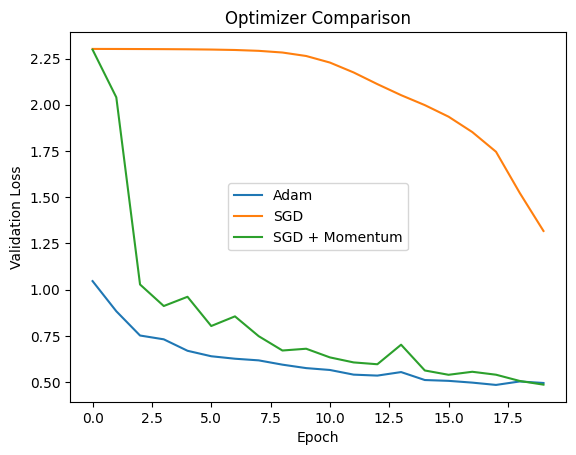

In [15]:
plt.plot(adam_history.history["val_loss"], label="Adam")
plt.plot(sgd_history.history["val_loss"], label="SGD")
plt.plot(momentum_history.history["val_loss"], label="SGD + Momentum")

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Optimizer Comparison")
plt.legend()
plt.show()

## 16. Compare Optimizer Validation Accuracy

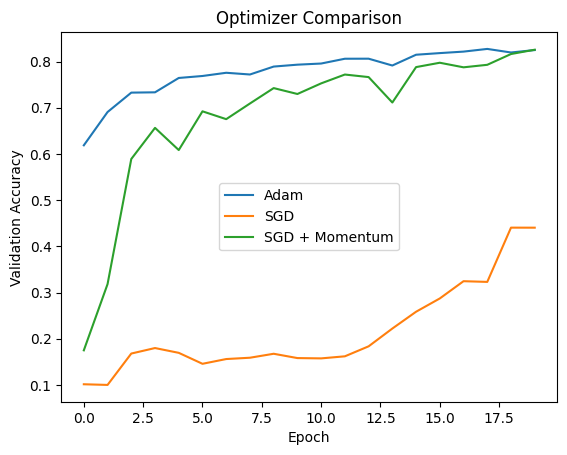

In [16]:
plt.plot(adam_history.history["val_accuracy"], label="Adam")
plt.plot(sgd_history.history["val_accuracy"], label="SGD")
plt.plot(momentum_history.history["val_accuracy"], label="SGD + Momentum")

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Optimizer Comparison")
plt.legend()
plt.show()

## 17. Optimizer Results

We evaluate the three optimizer versions on the same test set.

In [17]:
adam_test = adam_model.evaluate(x_test, y_test, verbose=0)
sgd_test = sgd_model.evaluate(x_test, y_test, verbose=0)
momentum_test = momentum_model.evaluate(x_test, y_test, verbose=0)

optimizer_results = pd.DataFrame({
    "Optimizer": ["Adam", "SGD", "SGD + Momentum"],
    "Test Accuracy": [
        adam_test[1],
        sgd_test[1],
        momentum_test[1]
    ]
})

optimizer_results

,Optimizer,Test Accuracy
0,Adam,0.819714
1,SGD,0.438857
2,SGD + Momentum,0.826000


# Train Model A and Model B

## 18. Train Model A

For the main comparison, we use Adam with learning rate 0.001.

Both custom models are trained for 20 epochs.

In [18]:
model_a.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start = time.time()

history_a = model_a.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=128,
    verbose=2
)

time_a = time.time() - start
time_per_epoch_a = time_a / 20

print("Average time per epoch:", time_per_epoch_a, "seconds")

Epoch 1/20
383/383 - 9s - 23ms/step - accuracy: 0.7918 - loss: 0.5823 - val_accuracy: 0.8543 - val_loss: 0.4054
Epoch 2/20
383/383 - 2s - 5ms/step - accuracy: 0.8657 - loss: 0.3731 - val_accuracy: 0.8828 - val_loss: 0.3396
Epoch 3/20
383/383 - 2s - 4ms/step - accuracy: 0.8848 - loss: 0.3237 - val_accuracy: 0.8917 - val_loss: 0.3065
Epoch 4/20
383/383 - 2s - 4ms/step - accuracy: 0.8933 - loss: 0.2951 - val_accuracy: 0.8937 - val_loss: 0.2893
Epoch 5/20
383/383 - 2s - 4ms/step - accuracy: 0.9022 - loss: 0.2707 - val_accuracy: 0.8887 - val_loss: 0.3023
Epoch 6/20
383/383 - 2s - 4ms/step - accuracy: 0.9087 - loss: 0.2532 - val_accuracy: 0.9048 - val_loss: 0.2629
Epoch 7/20
383/383 - 2s - 4ms/step - accuracy: 0.9114 - loss: 0.2424 - val_accuracy: 0.9023 - val_loss: 0.2689
Epoch 8/20
383/383 - 2s - 5ms/step - accuracy: 0.9173 - loss: 0.2269 - val_accuracy: 0.9129 - val_loss: 0.2409
Epoch 9/20
383/383 - 2s - 4ms/step - accuracy: 0.9201 - loss: 0.2176 - val_accuracy: 0.9105 - val_loss: 0.2444


## 19. Train Model B

The Adam version of Model B was already trained for 20 epochs during the optimizer comparison.

We use that trained model here.

In [19]:
model_b = adam_model
history_b = adam_history

# Train once more only for timing Model B clearly.
time_model_b = keras.models.clone_model(model_b)

time_model_b.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start = time.time()

time_history_b = time_model_b.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=128,
    verbose=2
)

time_b = time.time() - start
time_per_epoch_b = time_b / 20

print("Average time per epoch:", time_per_epoch_b, "seconds")

Epoch 1/20
383/383 - 7s - 19ms/step - accuracy: 0.3838 - loss: 1.6264 - val_accuracy: 0.5999 - val_loss: 1.0656
Epoch 2/20
383/383 - 2s - 5ms/step - accuracy: 0.6448 - loss: 0.9533 - val_accuracy: 0.6729 - val_loss: 0.8901
Epoch 3/20
383/383 - 2s - 4ms/step - accuracy: 0.6793 - loss: 0.8651 - val_accuracy: 0.6774 - val_loss: 0.8907
Epoch 4/20
383/383 - 2s - 4ms/step - accuracy: 0.6971 - loss: 0.8171 - val_accuracy: 0.6891 - val_loss: 0.8354
Epoch 5/20
383/383 - 2s - 4ms/step - accuracy: 0.7130 - loss: 0.7794 - val_accuracy: 0.7202 - val_loss: 0.7800
Epoch 6/20
383/383 - 2s - 4ms/step - accuracy: 0.7256 - loss: 0.7471 - val_accuracy: 0.7331 - val_loss: 0.7637
Epoch 7/20
383/383 - 3s - 7ms/step - accuracy: 0.7367 - loss: 0.7133 - val_accuracy: 0.7490 - val_loss: 0.6901
Epoch 8/20
383/383 - 2s - 4ms/step - accuracy: 0.7451 - loss: 0.6857 - val_accuracy: 0.7521 - val_loss: 0.6863
Epoch 9/20
383/383 - 2s - 4ms/step - accuracy: 0.7524 - loss: 0.6643 - val_accuracy: 0.7629 - val_loss: 0.6627


# Loss Curves

## 20. Model A Loss

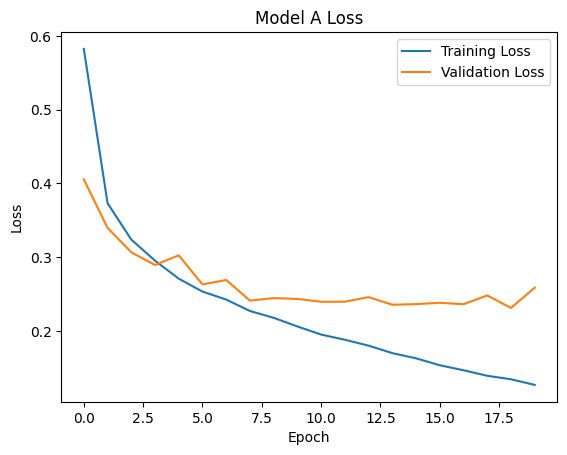

In [20]:
plt.plot(history_a.history["loss"], label="Training Loss")
plt.plot(history_a.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model A Loss")
plt.legend()
plt.show()

## 21. Model B Loss

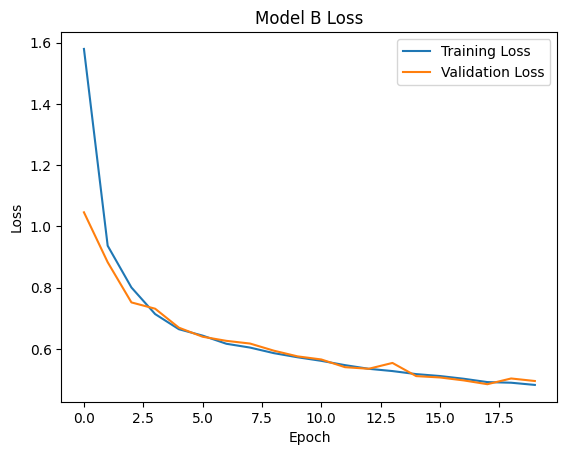

In [21]:
plt.plot(history_b.history["loss"], label="Training Loss")
plt.plot(history_b.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model B Loss")
plt.legend()
plt.show()

# Model Evaluation

## 22. Evaluate Model A

We calculate:

- Accuracy
- Precision
- Recall
- Confusion matrix

In [22]:
prob_a = model_a.predict(x_test, verbose=0)
pred_a = np.argmax(prob_a, axis=1)

accuracy_a = accuracy_score(y_test, pred_a)
precision_a = precision_score(y_test, pred_a, average="weighted", zero_division=0)
recall_a = recall_score(y_test, pred_a, average="weighted", zero_division=0)

print("Accuracy:", accuracy_a)
print("Precision:", precision_a)
print("Recall:", recall_a)

Accuracy: 0.908952380952381
Precision: 0.9125298937322748
Recall: 0.908952380952381


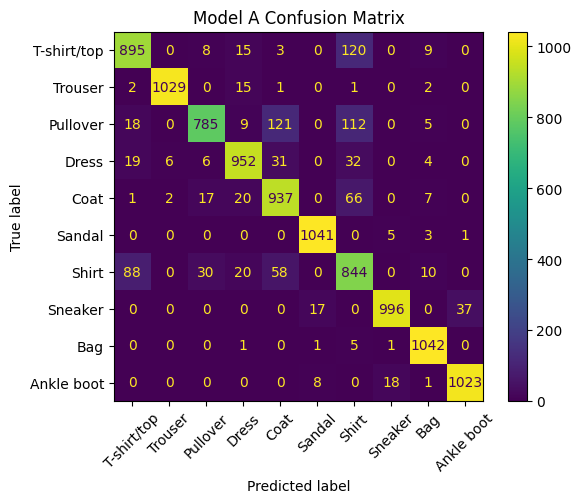

In [23]:
cm_a = confusion_matrix(y_test, pred_a)

display_a = ConfusionMatrixDisplay(
    confusion_matrix=cm_a,
    display_labels=class_names
)

display_a.plot(xticks_rotation=45)
plt.title("Model A Confusion Matrix")
plt.show()

In [24]:
print(classification_report(
    y_test,
    pred_a,
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

 T-shirt/top       0.87      0.85      0.86      1050
     Trouser       0.99      0.98      0.99      1050
    Pullover       0.93      0.75      0.83      1050
       Dress       0.92      0.91      0.91      1050
        Coat       0.81      0.89      0.85      1050
      Sandal       0.98      0.99      0.98      1050
       Shirt       0.72      0.80      0.76      1050
     Sneaker       0.98      0.95      0.96      1050
         Bag       0.96      0.99      0.98      1050
  Ankle boot       0.96      0.97      0.97      1050

    accuracy                           0.91     10500
   macro avg       0.91      0.91      0.91     10500
weighted avg       0.91      0.91      0.91     10500



## 23. Evaluate Model B

In [25]:
prob_b = model_b.predict(x_test, verbose=0)
pred_b = np.argmax(prob_b, axis=1)

accuracy_b = accuracy_score(y_test, pred_b)
precision_b = precision_score(y_test, pred_b, average="weighted", zero_division=0)
recall_b = recall_score(y_test, pred_b, average="weighted", zero_division=0)

print("Accuracy:", accuracy_b)
print("Precision:", precision_b)
print("Recall:", recall_b)

Accuracy: 0.8197142857142857
Precision: 0.8198010092495711
Recall: 0.8197142857142857


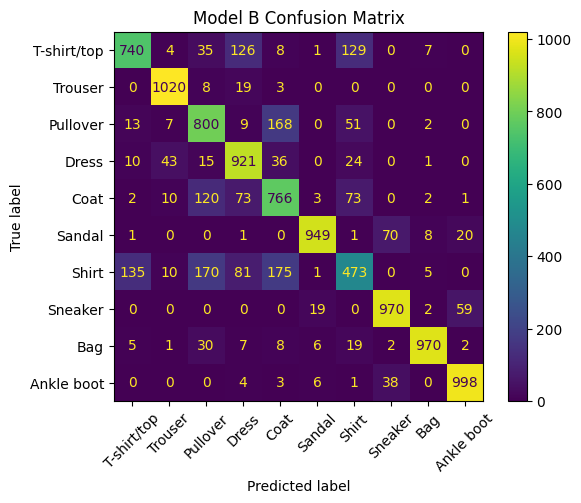

In [26]:
cm_b = confusion_matrix(y_test, pred_b)

display_b = ConfusionMatrixDisplay(
    confusion_matrix=cm_b,
    display_labels=class_names
)

display_b.plot(xticks_rotation=45)
plt.title("Model B Confusion Matrix")
plt.show()

In [27]:
print(classification_report(
    y_test,
    pred_b,
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

 T-shirt/top       0.82      0.70      0.76      1050
     Trouser       0.93      0.97      0.95      1050
    Pullover       0.68      0.76      0.72      1050
       Dress       0.74      0.88      0.80      1050
        Coat       0.66      0.73      0.69      1050
      Sandal       0.96      0.90      0.93      1050
       Shirt       0.61      0.45      0.52      1050
     Sneaker       0.90      0.92      0.91      1050
         Bag       0.97      0.92      0.95      1050
  Ankle boot       0.92      0.95      0.94      1050

    accuracy                           0.82     10500
   macro avg       0.82      0.82      0.82     10500
weighted avg       0.82      0.82      0.82     10500



# Model Size

## 24. Save the Models and Check File Size

The assignment asks for estimated model size on disk.

We save each model and then check its file size.

In [28]:
model_a.save("model_a.keras")
model_b.save("model_b.keras")

size_a = os.path.getsize("model_a.keras") / 1024
size_b = os.path.getsize("model_b.keras") / 1024

print("Model A size:", size_a, "KB")
print("Model B size:", size_b, "KB")

Model A size: 1277.197265625 KB
Model B size: 110.2373046875 KB


# Custom Model Comparison

## 25. Compare Model A and Model B

In [29]:
custom_results = pd.DataFrame({
    "Model": ["Model A", "Model B"],
    "Parameters": [
        model_a.count_params(),
        model_b.count_params()
    ],
    "Model Size (KB)": [
        size_a,
        size_b
    ],
    "Time per Epoch (s)": [
        time_per_epoch_a,
        time_per_epoch_b
    ],
    "Test Accuracy": [
        accuracy_a,
        accuracy_b
    ],
    "Precision": [
        precision_a,
        precision_b
    ],
    "Recall": [
        recall_a,
        recall_b
    ]
})

custom_results

,Model,Parameters,Model Size (KB),Time per Epoch (s),Test Accuracy,Precision,Recall
0,Model A,105866,1277.197266,2.093301,0.908952,0.912530,0.908952
1,Model B,5658,110.237305,2.089534,0.819714,0.819801,0.819714


# Lightweight Pre-trained Networks

We now compare our custom lightweight Model B with two pre-trained lightweight networks:

1. MobileNetV2
2. EfficientNetB0

Fashion-MNIST images are 28 x 28 grayscale images.

The pre-trained ImageNet models need RGB images, so we convert them to 64 x 64 x 3.

## 26. Prepare Data for Pre-trained Models

In [30]:
def prepare_image(image, label):
    image = tf.cast(image, tf.float32)
    image = tf.expand_dims(image, axis=-1)
    image = tf.image.resize(image, (64, 64))
    image = tf.image.grayscale_to_rgb(image)

    return image, label

In [31]:
train_data = tf.data.Dataset.from_tensor_slices((x_train_raw, y_train))
val_data = tf.data.Dataset.from_tensor_slices((x_val_raw, y_val))
test_data = tf.data.Dataset.from_tensor_slices((x_test_raw, y_test))

train_data = train_data.map(prepare_image).shuffle(10000).batch(128).prefetch(tf.data.AUTOTUNE)
val_data = val_data.map(prepare_image).batch(128).prefetch(tf.data.AUTOTUNE)
test_data = test_data.map(prepare_image).batch(128).prefetch(tf.data.AUTOTUNE)

# MobileNetV2

## 27. Build MobileNetV2

We remove the original ImageNet classifier and add our own 10-class output layer.

In [32]:
mobile_base = keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(64, 64, 3)
)

mobile_base.trainable = False

mobile_input = keras.Input(shape=(64, 64, 3))

x = keras.applications.mobilenet_v2.preprocess_input(mobile_input)
x = mobile_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)

mobile_output = layers.Dense(10, activation="softmax")(x)

mobile_model = keras.Model(mobile_input, mobile_output)

mobile_model.summary()

/tmp/ipykernel_2477/1525238871.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  mobile_base = keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 2, 2, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 28. Train MobileNetV2 - Frozen Base

First we train only the new output layer for 5 epochs.

In [33]:
mobile_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobile_model.fit(
    train_data,
    validation_data=val_data,
    epochs=5,
    verbose=2
)

Epoch 1/5
383/383 - 28s - 74ms/step - accuracy: 0.7817 - loss: 0.6368 - val_accuracy: 0.8463 - val_loss: 0.4487
Epoch 2/5
383/383 - 9s - 22ms/step - accuracy: 0.8528 - loss: 0.4123 - val_accuracy: 0.8551 - val_loss: 0.4213
Epoch 3/5
383/383 - 9s - 23ms/step - accuracy: 0.8679 - loss: 0.3719 - val_accuracy: 0.8619 - val_loss: 0.4068
Epoch 4/5
383/383 - 9s - 22ms/step - accuracy: 0.8744 - loss: 0.3485 - val_accuracy: 0.8611 - val_loss: 0.4007
Epoch 5/5
383/383 - 8s - 21ms/step - accuracy: 0.8796 - loss: 0.3332 - val_accuracy: 0.8611 - val_loss: 0.3983


## 29. Fine-tune MobileNetV2

We unfreeze only the last 20 layers.

A smaller learning rate is used for fine-tuning.

In [34]:
mobile_base.trainable = True

for layer in mobile_base.layers[:-20]:
    layer.trainable = False

mobile_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start = time.time()

mobile_history = mobile_model.fit(
    train_data,
    validation_data=val_data,
    epochs=15,
    verbose=2
)

mobile_time = time.time() - start

Epoch 1/15
383/383 - 37s - 96ms/step - accuracy: 0.7517 - loss: 0.8012 - val_accuracy: 0.8590 - val_loss: 0.4284
Epoch 2/15
383/383 - 10s - 25ms/step - accuracy: 0.8295 - loss: 0.5077 - val_accuracy: 0.8575 - val_loss: 0.4430
Epoch 3/15
383/383 - 9s - 24ms/step - accuracy: 0.8532 - loss: 0.4245 - val_accuracy: 0.8561 - val_loss: 0.4464
Epoch 4/15
383/383 - 9s - 23ms/step - accuracy: 0.8696 - loss: 0.3729 - val_accuracy: 0.8628 - val_loss: 0.4288
Epoch 5/15
383/383 - 9s - 23ms/step - accuracy: 0.8813 - loss: 0.3328 - val_accuracy: 0.8662 - val_loss: 0.4135
Epoch 6/15
383/383 - 10s - 27ms/step - accuracy: 0.8923 - loss: 0.3006 - val_accuracy: 0.8707 - val_loss: 0.3997
Epoch 7/15
383/383 - 10s - 26ms/step - accuracy: 0.9026 - loss: 0.2728 - val_accuracy: 0.8750 - val_loss: 0.3860
Epoch 8/15
383/383 - 9s - 23ms/step - accuracy: 0.9101 - loss: 0.2521 - val_accuracy: 0.8765 - val_loss: 0.3778
Epoch 9/15
383/383 - 9s - 24ms/step - accuracy: 0.9162 - loss: 0.2318 - val_accuracy: 0.8781 - val_l

## 30. Evaluate MobileNetV2

In [35]:
mobile_loss, mobile_accuracy = mobile_model.evaluate(test_data, verbose=0)

mobile_pred_prob = mobile_model.predict(test_data, verbose=0)
mobile_pred = np.argmax(mobile_pred_prob, axis=1)

mobile_precision = precision_score(y_test, mobile_pred, average="weighted", zero_division=0)
mobile_recall = recall_score(y_test, mobile_pred, average="weighted", zero_division=0)

print("Accuracy:", mobile_accuracy)
print("Precision:", mobile_precision)
print("Recall:", mobile_recall)
print("Parameters:", mobile_model.count_params())

Accuracy: 0.87971431016922
Precision: 0.8801452703172336
Recall: 0.8797142857142857
Parameters: 2270794


In [36]:
mobile_model.save("mobilenetv2.keras")
mobile_size = os.path.getsize("mobilenetv2.keras") / (1024 * 1024)

print("MobileNetV2 size:", mobile_size, "MB")

MobileNetV2 size: 18.53582191467285 MB


# EfficientNetB0

## 31. Build EfficientNetB0

In [37]:
efficient_base = keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(64, 64, 3)
)

efficient_base.trainable = False

efficient_input = keras.Input(shape=(64, 64, 3))

x = efficient_base(efficient_input, training=False)
x = layers.GlobalAveragePooling2D()(x)

efficient_output = layers.Dense(10, activation="softmax")(x)

efficient_model = keras.Model(efficient_input, efficient_output)

efficient_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 2, 2, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,062,381 (15.50 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 32. Train EfficientNetB0 - Frozen Base

In [38]:
efficient_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

efficient_model.fit(
    train_data,
    validation_data=val_data,
    epochs=5,
    verbose=2
)

Epoch 1/5
383/383 - 57s - 149ms/step - accuracy: 0.7966 - loss: 0.6108 - val_accuracy: 0.8573 - val_loss: 0.4077
Epoch 2/5
383/383 - 9s - 23ms/step - accuracy: 0.8561 - loss: 0.4076 - val_accuracy: 0.8688 - val_loss: 0.3654
Epoch 3/5
383/383 - 10s - 27ms/step - accuracy: 0.8659 - loss: 0.3738 - val_accuracy: 0.8767 - val_loss: 0.3431
Epoch 4/5
383/383 - 9s - 24ms/step - accuracy: 0.8730 - loss: 0.3551 - val_accuracy: 0.8780 - val_loss: 0.3353
Epoch 5/5
383/383 - 9s - 24ms/step - accuracy: 0.8770 - loss: 0.3404 - val_accuracy: 0.8820 - val_loss: 0.3251


## 33. Fine-tune EfficientNetB0

In [39]:
efficient_base.trainable = True

for layer in efficient_base.layers[:-20]:
    layer.trainable = False

efficient_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start = time.time()

efficient_history = efficient_model.fit(
    train_data,
    validation_data=val_data,
    epochs=15,
    verbose=2
)

efficient_time = time.time() - start

Epoch 1/15
383/383 - 60s - 155ms/step - accuracy: 0.7759 - loss: 0.6759 - val_accuracy: 0.8396 - val_loss: 0.4822
Epoch 2/15
383/383 - 10s - 25ms/step - accuracy: 0.8284 - loss: 0.5079 - val_accuracy: 0.8554 - val_loss: 0.4329
Epoch 3/15
383/383 - 10s - 26ms/step - accuracy: 0.8440 - loss: 0.4527 - val_accuracy: 0.8649 - val_loss: 0.4008
Epoch 4/15
383/383 - 10s - 25ms/step - accuracy: 0.8580 - loss: 0.4167 - val_accuracy: 0.8714 - val_loss: 0.3793
Epoch 5/15
383/383 - 10s - 27ms/step - accuracy: 0.8639 - loss: 0.3909 - val_accuracy: 0.8750 - val_loss: 0.3636
Epoch 6/15
383/383 - 10s - 25ms/step - accuracy: 0.8690 - loss: 0.3729 - val_accuracy: 0.8787 - val_loss: 0.3514
Epoch 7/15
383/383 - 10s - 25ms/step - accuracy: 0.8730 - loss: 0.3544 - val_accuracy: 0.8821 - val_loss: 0.3417
Epoch 8/15
383/383 - 10s - 25ms/step - accuracy: 0.8786 - loss: 0.3431 - val_accuracy: 0.8833 - val_loss: 0.3341
Epoch 9/15
383/383 - 10s - 26ms/step - accuracy: 0.8827 - loss: 0.3297 - val_accuracy: 0.8867 -

## 34. Evaluate EfficientNetB0

In [40]:
efficient_loss, efficient_accuracy = efficient_model.evaluate(test_data, verbose=0)

efficient_pred_prob = efficient_model.predict(test_data, verbose=0)
efficient_pred = np.argmax(efficient_pred_prob, axis=1)

efficient_precision = precision_score(y_test, efficient_pred, average="weighted", zero_division=0)
efficient_recall = recall_score(y_test, efficient_pred, average="weighted", zero_division=0)

print("Accuracy:", efficient_accuracy)
print("Precision:", efficient_precision)
print("Recall:", efficient_recall)
print("Parameters:", efficient_model.count_params())

Accuracy: 0.8938094973564148
Precision: 0.8936333049233938
Recall: 0.8938095238095238
Parameters: 4062381


In [41]:
efficient_model.save("efficientnetb0.keras")
efficient_size = os.path.getsize("efficientnetb0.keras") / (1024 * 1024)

print("EfficientNetB0 size:", efficient_size, "MB")

EfficientNetB0 size: 26.719125747680664 MB


# Final Comparison

## 35. Compare Model B with MobileNetV2 and EfficientNetB0

The assignment asks us to focus on:

- Accuracy
- Memory footprint
- Computational cost

In [42]:
final_results = pd.DataFrame({
    "Model": [
        "Custom Model B",
        "MobileNetV2",
        "EfficientNetB0"
    ],
    "Parameters": [
        model_b.count_params(),
        mobile_model.count_params(),
        efficient_model.count_params()
    ],
    "Model Size (MB)": [
        size_b / 1024,
        mobile_size,
        efficient_size
    ],
    "Test Accuracy": [
        accuracy_b,
        mobile_accuracy,
        efficient_accuracy
    ]
})

final_results

,Model,Parameters,Model Size (MB),Test Accuracy
0,Custom Model B,5658,0.107654,0.819714
1,MobileNetV2,2270794,18.535822,0.879714
2,EfficientNetB0,4062381,26.719126,0.893809


## 36. Simple Discussion Guide

After running the notebook, use your actual results to discuss the following.

### Model A vs Model B

- Which model has higher accuracy?
- How many parameters does each model have?
- Which model has the smaller file size?
- Which model has lower training time per epoch?
- Did reducing parameters reduce accuracy?

### Optimizers

- Did Adam converge faster than normal SGD?
- Did momentum improve SGD?
- Which optimizer gave the best test accuracy?

### Model B vs Pre-trained Models

- Does MobileNetV2 or EfficientNetB0 improve accuracy?
- How much larger are the pre-trained models?
- Is the extra accuracy worth the larger memory requirement?
- Which model is more suitable for a very small embedded device?
- Which model is more suitable for a Raspberry Pi or stronger edge device?

### Main Trade-off

A model with the highest accuracy is not always the best model for an edge device.

For edge deployment we should consider:

**Accuracy + Memory + Computational Cost**